# Figure 1.1 - AP

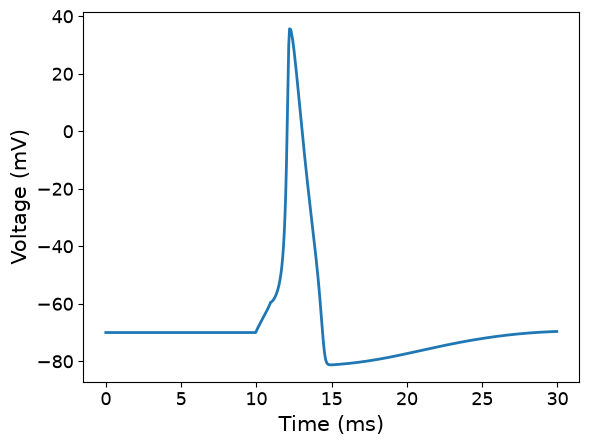

In [1]:
import matplotlib.pyplot as plt
import numpy as np

# ============================================================
# Hodgkin–Huxley Model
# ============================================================

class HHModel:

    class Gate:
        alpha, beta, state = 0, 0, 0

        def update(self, deltaTms):
            alphaState = self.alpha * (1 - self.state)
            betaState = self.beta * self.state
            self.state += deltaTms * (alphaState - betaState)

        def setInfiniteState(self):
            self.state = self.alpha / (self.alpha + self.beta)

    ENa, EK, EKleak = 115, -12, 10.6
    gNa, gK, gKleak = 120, 36, 0.3
    m, n, h = Gate(), Gate(), Gate()
    Cm = 1

    def __init__(self, startingVoltage=0):
        self.Vm = startingVoltage
        self.UpdateGateTimeConstants(startingVoltage)
        self.m.setInfiniteState()
        self.n.setInfiniteState()
        self.h.setInfiniteState()
        self.INa = 0
        self.IK = 0
        self.IKleak = 0
        self.Isum = 0

    def UpdateGateTimeConstants(self, Vm):
        self.n.alpha = .01 * ((10 - Vm) / (np.exp((10 - Vm) / 10) - 1))
        self.n.beta = .125 * np.exp(-Vm / 80)
        self.m.alpha = .1 * ((25 - Vm) / (np.exp((25 - Vm) / 10) - 1))
        self.m.beta = 4 * np.exp(-Vm / 18)
        self.h.alpha = .07 * np.exp(-Vm / 20)
        self.h.beta = 1 / (np.exp((30 - Vm) / 10) + 1)

    def UpdateCellVoltage(self, stimulusCurrent, deltaTms):
        self.INa = (self.m.state ** 3) * self.gNa * self.h.state * (self.Vm - self.ENa)
        self.IK = (self.n.state ** 4) * self.gK * (self.Vm - self.EK)
        self.IKleak = self.gKleak * (self.Vm - self.EKleak)
        self.Isum = stimulusCurrent - self.INa - self.IK - self.IKleak
        self.Vm += deltaTms * self.Isum / self.Cm

    def UpdateGateStates(self, deltaTms):
        self.n.update(deltaTms)
        self.m.update(deltaTms)
        self.h.update(deltaTms)

    def Iterate(self, stimulusCurrent=0, deltaTms=0.05):
        self.UpdateGateTimeConstants(self.Vm)
        self.UpdateCellVoltage(stimulusCurrent, deltaTms)
        self.UpdateGateStates(deltaTms)

    def ComputeConductances(self):
        GNa_t = self.gNa * self.m.state ** 3 * self.h.state
        GK_t = self.gK * self.n.state ** 4
        return GNa_t, GK_t


# ============================================================
# SIMULATION
# ============================================================

hh = HHModel()

pointCount = 600
dt = 0.05
times = np.arange(pointCount) * dt

V_HH = np.empty(pointCount)
n_HH = np.empty(pointCount)
m_HH = np.empty(pointCount)
h_HH = np.empty(pointCount)

INa = np.empty(pointCount)
IK = np.empty(pointCount)
IKleak = np.empty(pointCount)
Isum = np.empty(pointCount)

GNa_HH = np.empty(pointCount)
GK_HH = np.empty(pointCount)

stim = 0*np.ones(pointCount)
stim[200:220] = 11.5

for i in range(pointCount):
    hh.Iterate(stimulusCurrent=stim[i], deltaTms=dt)

    V_HH[i] = hh.Vm
    n_HH[i] = hh.n.state
    m_HH[i] = hh.m.state
    h_HH[i] = hh.h.state

    INa[i] = hh.INa
    IK[i] = hh.IK
    IKleak[i] = hh.IKleak
    Isum[i] = hh.Isum

    GNa_HH[i], GK_HH[i] = hh.ComputeConductances()

# ============================================================
# PLOTS
# ============================================================

plt.figure()
plt.plot(times, V_HH - 70, linewidth=2)
plt.xlabel("Time (ms)", fontsize=15)
plt.ylabel("Voltage (mV)", fontsize=15)

plt.tick_params(axis='both', which='major', labelsize=13)

plt.show()

# Figure 1.9 - Conductances responses

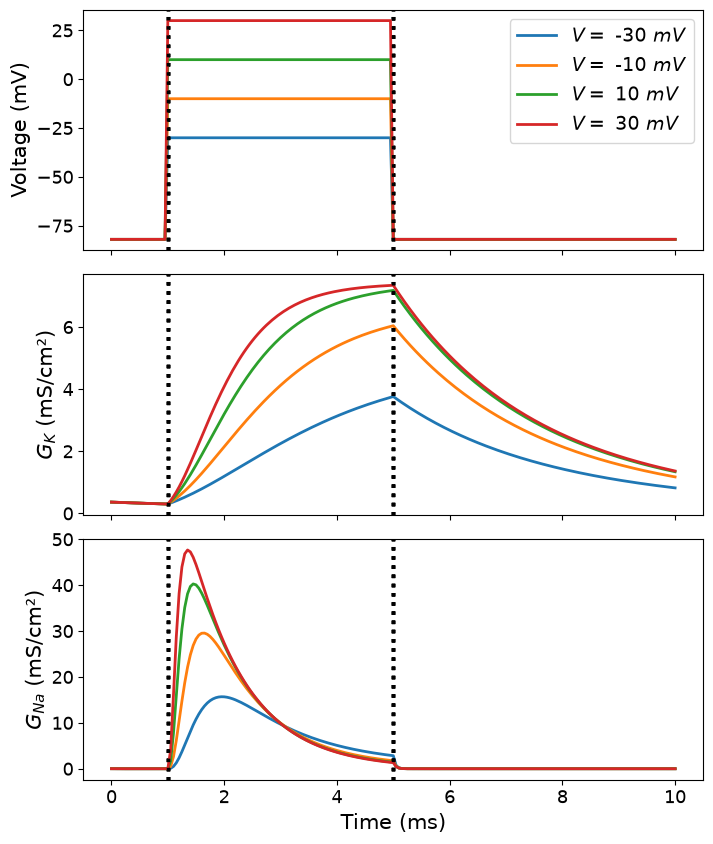

In [2]:
import matplotlib.pyplot as plt
import numpy as np

fig, axs = plt.subplots(3, 1, figsize=(8, 10), sharex=True, gridspec_kw={'height_ratios': [1, 1, 1]})
gNa, gK, gKleak = 120, 36, 0.3
ENa, EK, EKleak = 115, -12, 10.6
# Time parameters
dt = 0.05
T = 10# ms
Tt = np.arange(0, T + dt, dt)
voltages = [40, 60, 80, 100]  # mV

V=np.ones(len(Tt))*(-12)
n=np.zeros(len(Tt))
m=np.zeros(len(Tt))
h=np.zeros(len(Tt))

[n[0],m[0],h[0]]=[0.317, 0.05, 0.6]

# HH model gating variables
for V_step in voltages:
  for j in range(int(1/dt), int(5/dt)):
    V[j]=V_step
    for i in range(len(Tt)-1):

      alpha_n= 0.01*(10 - (V[i]))/ (np.exp((10 - V[i])/10) - 1)
      beta_n=0.125 * np.exp(V[i]/80)

      alpha_m=0.1*(25 - V[i])/(np.exp((25 - V[i])/10) - 1)
      beta_m=4.0 * np.exp(-V[i]/18)

      alpha_h=0.07 * np.exp(-V[i]/20)
      beta_h=1 / (np.exp((30 - V[i])/10) + 1)

      dn = alpha_n*(1-n[i]) - beta_n*n[i]
      dm = alpha_m*(1-m[i]) - beta_m*m[i]
      dh = alpha_h*(1-h[i]) - beta_h*h[i]

      n[i+1]=n[i]+dn*dt
      m[i+1]=m[i]+dm*dt
      h[i+1]=h[i]+dh*dt

  GK = gK * n**4
  GNa = gNa* m**3 * h

  plt.subplot(3, 1, 1)
  plt.plot(Tt, V-70, linewidth=2, label=fr'$V=$ {V_step-70} $mV$')
  plt.axvline(x=1, color='k', linestyle=':', linewidth=2.5)
  plt.axvline(x=5, color='k', linestyle=':', linewidth=2.5)
  plt.ylabel('Voltage (mV)', fontsize=15)
  plt.tick_params(axis='both', which='major', labelsize=13)
  plt.legend(prop={'size': 14})

  plt.subplot(3, 1, 2)
  plt.plot(Tt, gK * n**4, linewidth=2)
  plt.axvline(x=1, color='k', linestyle=':', linewidth=2.5)
  plt.axvline(x=5, color='k', linestyle=':', linewidth=2.5)
  plt.ylabel('$G_K$ (mS/cm²)', fontsize=15)
  plt.tick_params(axis='both', which='major', labelsize=13)

  plt.subplot(3, 1, 3)
  plt.plot(Tt, gNa* m**3 * h, linewidth=2)
  plt.axvline(x=1, color='k', linestyle=':', linewidth=2.5)
  plt.axvline(x=5, color='k', linestyle=':', linewidth=2.5)
  plt.ylabel('$G_{Na}$ (mS/cm²)', fontsize=15)
  plt.tick_params(axis='both', which='major', labelsize=13)

plt.subplots_adjust(hspace=0.1)
plt.tick_params(axis='both', which='major', labelsize=13)
axs[0].tick_params(labelbottom=False)
axs[1].tick_params(labelbottom=False)
axs[2].set_xlabel('Time (ms)', fontsize=15)


plt.show()

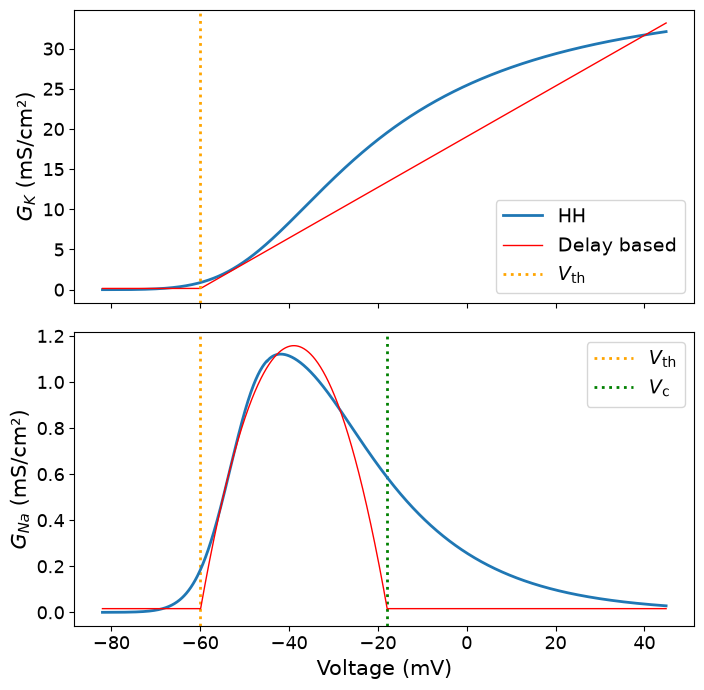

In [3]:
import matplotlib.pyplot as plt
import numpy as np

fig, axs = plt.subplots(2, 1, figsize=(8, 8), sharex=True, gridspec_kw={'height_ratios': [1, 1]})
gNa, gK, gKleak = 120, 36, 0.3
ENa, EK, EKleak = 115, -12, 10.6
# Time parameters
dt = 0.1
T = 10# ms

Vv = np.arange(-12, 115, dt)
n=np.zeros(len(Vv))
m=np.zeros(len(Vv))
h=np.zeros(len(Vv))
n2=np.zeros(len(Vv))
m2=np.zeros(len(Vv))
h2=np.zeros(len(Vv))

V_th= -60
V_cut = -18
C_Na = 17.4
C_K = 33.1
G_Namin = 0.01600
G_Kmin=9.5*G_Namin

for i in range(len(Vv)-1):

      alpha_n= 0.01*(10 - (Vv[i]))/ (np.exp((10 - Vv[i])/10) - 1)
      beta_n=0.125 * np.exp(-Vv[i]/80)

      alpha_m=0.1*(25 - Vv[i])/(np.exp((25 - Vv[i])/10) - 1)
      beta_m=4.0 * np.exp(-Vv[i]/18)

      alpha_h=0.07 * np.exp(-Vv[i]/20)
      beta_h=1 / (np.exp((30 - Vv[i])/10) + 1)

      dn = alpha_n*(1-n[i]) - beta_n*n[i]
      dm = alpha_m*(1-m[i]) - beta_m*m[i]
      dh = alpha_h*(1-h[i]) - beta_h*h[i]
      n[i+1]=n[i]+dn*dt
      m[i+1]=m[i]+dm*dt
      h[i+1]=h[i]+dh*dt

      idx_m = i
      idx_h = i
      idx_k = i

      if min(idx_m, idx_h, idx_k) < 0:
            continue

      Vm_ = Vv[idx_m]
      Vh_ = Vv[idx_h]
      VK_ = Vv[idx_k]

      h2[i+1]=max(V_cut-(Vh_-70),0)/(V_cut-(EK-70))
      m2[i+1]=max((VK_-70)-V_th,0)/((ENa-70)-V_th)
      n2[i+1]=max((Vm_-70)-V_th, 0)/((ENa-70)-V_th)



GK = gK * n**4
GNa = gNa* m**3 * h

plt.subplot(2, 1, 1)
plt.plot(Vv-70, gK * n**4, linewidth=2, label='HH')
plt.plot(Vv-70, G_Kmin+C_K * n2, color='r', linewidth=1, label='Delay based')
plt.axvline(x=V_th, color='orange', linestyle=':', linewidth=2, label=r'$V_{\text{th}}$')
plt.ylabel('$G_K$ (mS/cm²)', fontsize=15)
plt.tick_params(axis='both', which='major', labelsize=13)
plt.legend(prop={'size': 14})

plt.subplot(2, 1, 2)
plt.axvline(x=V_th, color='orange', linestyle=':', linewidth=2, label=r'$V_{\text{th}}$')
plt.axvline(x=V_cut, color='g', linestyle=':', linewidth=2, label=r'$V_{\text{c}}$')
plt.plot(Vv-70, gNa* m**3 * h, linewidth=2)
plt.plot(Vv-70, G_Namin+C_Na* m2 * h2, color='r', linewidth=1)
plt.ylabel('$G_{Na}$ (mS/cm²)', fontsize=15)
plt.tick_params(axis='both', which='major', labelsize=13)
plt.subplots_adjust(hspace=0.1)
plt.tick_params(axis='both', which='major', labelsize=13)
plt.legend(prop={'size': 14})

axs[0].tick_params(labelbottom=False)
axs[1].tick_params(axis='both', which='major', labelsize=13)
axs[1].set_xlabel('Voltage (mV)', fontsize=15)

plt.show()

#Figure 1.11 AP and evolution of sodium and potassium conductances

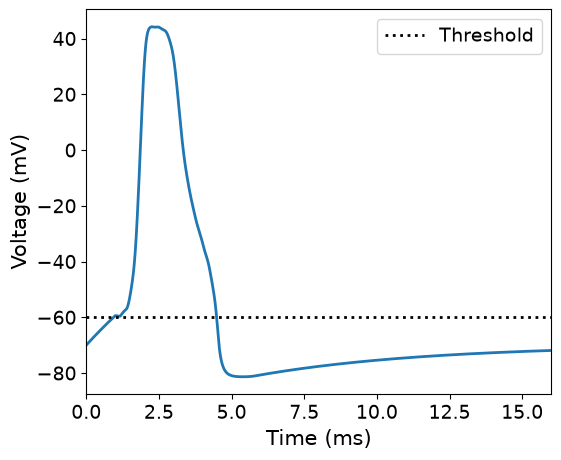

In [4]:
import numpy as np
import matplotlib.pyplot as plt

T = 20
p = 10**3
dt = 1/p
V_Na = 45
V_K = -82
V0 = -70
Cm = 1
V_th = -60
G_Namin = 0.01600
V_cut = -18.00000
C_Na = 36.96
C_K = 13.125
tau_m = 0.19903
tau_h = 2.75768
tau_K = 1.3
G_Kmin = 9.5 * G_Namin

Tt = np.arange(0, T + dt, dt)

V = V0 * np.ones_like(Tt)
m = np.zeros_like(Tt)
h = np.zeros_like(Tt)
n = np.zeros_like(Tt)
Gk = G_Kmin * np.ones_like(Tt)
GNa = G_Namin * np.ones_like(Tt)
I = np.zeros_like(Tt)

I_stim = 11.5
for i in range(int(0 / dt), int(1 / dt)):
    I[i] = I_stim

for i in range(len(Tt) - 1):

    # Delayed indices
    im = i - int(tau_m * p)
    ih = i - int(tau_h * p)
    iK = i - int(tau_K * p)

    # Use V0 if index is negative
    Vm = V[im] if im >= 0 else V0
    Vh = V[ih] if ih >= 0 else V0
    VK = V[iK] if iK >= 0 else V0

    h[i] = max(V_cut - Vh, 0) / (V_cut - V_K)
    m[i] = max(Vm - V_th, 0) / (V_Na - V_th)
    n[i] = max(VK - V_th, 0) / (V_Na - V_th)

    GNa[i] = G_Namin + C_Na * m[i] * h[i]
    Gk[i] = G_Kmin + C_K * n[i]

    dVdt = -1 / Cm * (Gk[i] * (V[i] - V_K) +
                      GNa[i] * (V[i] - V_Na) -
                      I[i])

    V[i + 1] = V[i] + dt * dVdt

plt.figure(figsize=(6, 5))
plt.plot(Tt, V, linewidth=2)
plt.axhline(y=V_th, color='k', linestyle=':', linewidth=2, label='Threshold')
plt.tick_params(axis='both', which='major', labelsize=14)
plt.legend(prop={'size': 14})
plt.xlim([0,16])
plt.xlabel('Time (ms)', fontsize=15)
plt.ylabel('Voltage (mV)', fontsize=15)
plt.show()


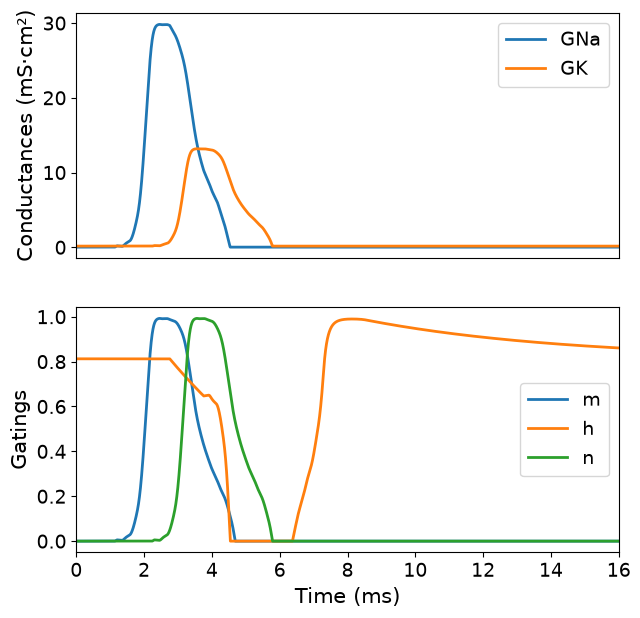

In [5]:
fig, axs = plt.subplots(2, 1, figsize=(7, 7), sharex=True)

# ---- First subplot ----
axs[0].plot(Tt, GNa, label='GNa', linewidth=2)
axs[0].plot(Tt, Gk, label='GK', linewidth=2)
axs[0].tick_params(axis='y', labelsize=14)
axs[0].legend(prop={'size': 14})
axs[0].set_ylabel('Conductances (mS·cm²)', fontsize=15)

# Hide x ticks & labels on first plot
axs[0].tick_params(axis='x', which='both', bottom=False, labelbottom=False)

# ---- Second subplot ----
axs[1].plot(Tt, m, label='m', linewidth=2)
axs[1].plot(Tt, h, label='h', linewidth=2)
axs[1].plot(Tt, n, label='n', linewidth=2)
axs[1].tick_params(axis='both', which='major', labelsize=14)
axs[1].legend(prop={'size': 14})
axs[1].set_ylabel('Gatings', fontsize=15)
axs[1].set_xlabel('Time (ms)', fontsize=15)

# ---- Common x-axis limits ----
axs[1].set_xlim(0, 16)

plt.show()



#Figure 1.12 - Sub, Sup

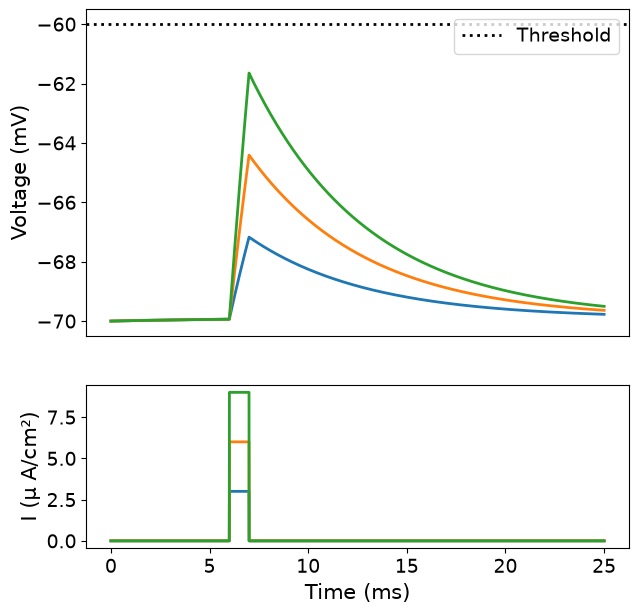

In [6]:
import numpy as np
import matplotlib.pyplot as plt

T = 25
p = 10**3
dt = 1/p
V_Na = 45
V_K = -82
V0 = -70
Cm = 1
V_th = -60
G_Namin = 0.01600
V_cut = -18.00000
C_Na = 36.96
C_K = 13.125
tau_m = 0.19903
tau_h = 2.75768
tau_K = 1.3
G_Kmin = 9.5 * G_Namin

Tt = np.arange(0, T + dt, dt)

V = V0 * np.ones_like(Tt)
m = np.zeros_like(Tt)
h = np.zeros_like(Tt)
n = np.zeros_like(Tt)
Gk = G_Kmin * np.ones_like(Tt)
GNa = G_Namin * np.ones_like(Tt)
I = np.zeros_like(Tt)


I_stim_all=[3,6,9]
fig, axs = plt.subplots(
    2, 1,
    figsize=(7, 7),
    sharex=True,
    gridspec_kw={'height_ratios': [2, 1]}
)

for j in range(0,3):
  I_stim = I_stim_all[j]
  for i in range(int(6 / dt), int(7 / dt)):
    I[i] = I_stim

  for i in range(len(Tt) - 1):

    # Delayed indices
    im = i - int(tau_m * p)
    ih = i - int(tau_h * p)
    iK = i - int(tau_K * p)

    # Use V0 if index is negative
    Vm = V[im] if im >= 0 else V0
    Vh = V[ih] if ih >= 0 else V0
    VK = V[iK] if iK >= 0 else V0

    h[i] = max(V_cut - Vh, 0) / (V_cut - V_K)
    m[i] = max(Vm - V_th, 0) / (V_Na - V_th)
    n[i] = max(VK - V_th, 0) / (V_Na - V_th)

    GNa[i] = G_Namin + C_Na * m[i] * h[i]
    Gk[i] = G_Kmin + C_K * n[i]

    dVdt = -1 / Cm * (Gk[i] * (V[i] - V_K) +
                      GNa[i] * (V[i] - V_Na) -
                      I[i])

    V[i + 1] = V[i] + dt * dVdt

  axs[0].plot(Tt, V, linewidth=2)
  axs[1].plot(Tt, I, linewidth=2)

# ---- First subplot ----
axs[0].tick_params(axis='y', labelsize=14)
axs[0].set_ylabel('Voltage (mV)', fontsize=15)
axs[0].axhline(y=V_th, color='k', linestyle=':', linewidth=2, label='Threshold')
axs[0].legend(prop={'size': 14},loc='upper right')
# Hide x ticks & labels on first plot
axs[0].tick_params(axis='x', which='both', bottom=False, labelbottom=False)

# ---- Second subplot ----
axs[1].tick_params(axis='both', which='major', labelsize=14)
axs[1].set_ylabel('I (μ A/cm²)', fontsize=15)
axs[1].set_xlabel('Time (ms)', fontsize=15)

plt.show()


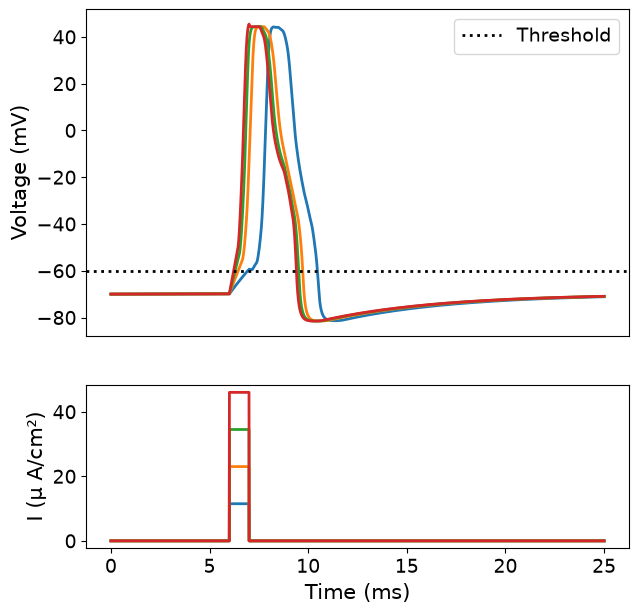

In [7]:
import numpy as np
import matplotlib.pyplot as plt

T = 25
p = 10**3
dt = 1/p
V_Na = 45
V_K = -82
V0 = -70
Cm = 1
V_th = -60
G_Namin = 0.01600
V_cut = -18.00000
C_Na = 36.96
C_K = 13.125
tau_m = 0.19903
tau_h = 2.75768
tau_K = 1.3
G_Kmin = 9.5 * G_Namin

Tt = np.arange(0, T + dt, dt)

V = V0 * np.ones_like(Tt)
m = np.zeros_like(Tt)
h = np.zeros_like(Tt)
n = np.zeros_like(Tt)
Gk = G_Kmin * np.ones_like(Tt)
GNa = G_Namin * np.ones_like(Tt)
I = np.zeros_like(Tt)


I_stim_all=[11.5,23,34.5,46]
fig, axs = plt.subplots(
    2, 1,
    figsize=(7, 7),
    sharex=True,
    gridspec_kw={'height_ratios': [2, 1]}
)

for j in range(0,4):
  I_stim = I_stim_all[j]
  for i in range(int(6 / dt), int(7 / dt)):
    I[i] = I_stim

  for i in range(len(Tt) - 1):

    # Delayed indices
    im = i - int(tau_m * p)
    ih = i - int(tau_h * p)
    iK = i - int(tau_K * p)

    # Use V0 if index is negative
    Vm = V[im] if im >= 0 else V0
    Vh = V[ih] if ih >= 0 else V0
    VK = V[iK] if iK >= 0 else V0

    h[i] = max(V_cut - Vh, 0) / (V_cut - V_K)
    m[i] = max(Vm - V_th, 0) / (V_Na - V_th)
    n[i] = max(VK - V_th, 0) / (V_Na - V_th)

    GNa[i] = G_Namin + C_Na * m[i] * h[i]
    Gk[i] = G_Kmin + C_K * n[i]

    dVdt = -1 / Cm * (Gk[i] * (V[i] - V_K) +
                      GNa[i] * (V[i] - V_Na) -
                      I[i])

    V[i + 1] = V[i] + dt * dVdt

  axs[0].plot(Tt, V, linewidth=2)
  axs[1].plot(Tt, I, linewidth=2)

# ---- First subplot ----
axs[0].tick_params(axis='y', labelsize=14)
axs[0].set_ylabel('Voltage (mV)', fontsize=15)
axs[0].axhline(y=V_th, color='k', linestyle=':', linewidth=2, label='Threshold')
axs[0].legend(prop={'size': 14},loc='upper right')
# Hide x ticks & labels on first plot
axs[0].tick_params(axis='x', which='both', bottom=False, labelbottom=False)

# ---- Second subplot ----
axs[1].tick_params(axis='both', which='major', labelsize=14)
axs[1].set_ylabel('I (μ A/cm²)', fontsize=15)
axs[1].set_xlabel('Time (ms)', fontsize=15)

plt.show()

# Figure 1.13 - Sigmoid

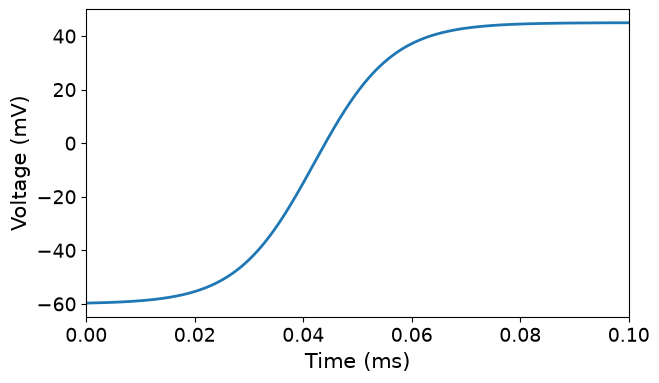

In [8]:
"""
Fast depolarization phase as a sigmoid (logistic upstroke).

Reproduces the closed-form solution of the upstroke:

    V(t) = V_th + (V_Na - V_th) / (1 + B * exp(-r * (t - t0)))

with
    B = (V_Na - V0) / (V0 - V_th)
    r = (C_Na * hbar / C_m) * (V_Na - V_th)
    hbar = (V_c - V_th) / (V_c - V_K)
"""

import numpy as np
import matplotlib.pyplot as plt

# ---- model parameters (Table 1.1) ----
V_K   = -82.0     # mV
V_Na  =  45.0     # mV
V_th  = -60.0     # mV
V_c   = -18.0     # mV
C_Na  =  36.96    # mS/cm^2
C_m   =   1.0     # uF/cm^2

# steady inactivation during the upstroke
h_bar = (V_c - V_th) / (V_c - V_K)

# logistic rate
r = (C_Na * h_bar / C_m) * (V_Na - V_th)

# ---------------------------------------------------------------
# Two ways to draw the curve:
#
#   USE_TRUE_PARAMETERS = True  -> uses the physical rate r above
#       (upstroke is very steep, saturates within ~0.006 ms).
#
#   USE_TRUE_PARAMETERS = False -> illustrative sigmoid centred in
#       the plotting window (matches the look of the book figure:
#       midpoint near t_half, gentle slope across 0..0.1 ms).
# ---------------------------------------------------------------
USE_TRUE_PARAMETERS = False

if USE_TRUE_PARAMETERS:
    eps = 1.0e-3
    V0  = V_th + eps
    t0  = 0.0
    B   = (V_Na - V0) / (V0 - V_th)
    def V(t):
        return V_th + (V_Na - V_th) / (1.0 + B * np.exp(-r * (t - t0)))
else:
    t_half = 0.042     # ms, midpoint of the visible transition
    k      = 140.0     # 1/ms, controls steepness (smaller = gentler)
    def V(t):
        return V_th + (V_Na - V_th) / (1.0 + np.exp(-k * (t - t_half)))

# ---- time axis (ms) ----
t = np.linspace(0.0, 0.10, 400)

# ---- plot ----
fig, ax = plt.subplots(figsize=(7, 4))
# ax.plot(t, V(t), color="#f5921b", linewidth=2)
ax.plot(t, V(t), linewidth=2)

# ax.set_title("Depolarization phase as a sigmoid")
ax.set_xlabel('Time (ms)', fontsize=15)
ax.set_ylabel('Voltage (mV)', fontsize=15)
ax.set_xlim(0.0, 0.10)
ax.set_ylim(-65, 50)
# ax.grid(True, color="0.85", linewidth=0.6)
ax.set_axisbelow(True)
ax.tick_params(axis='both', which='major', labelsize=14)
plt.show()

# Figure 1.14 - Second stimulus

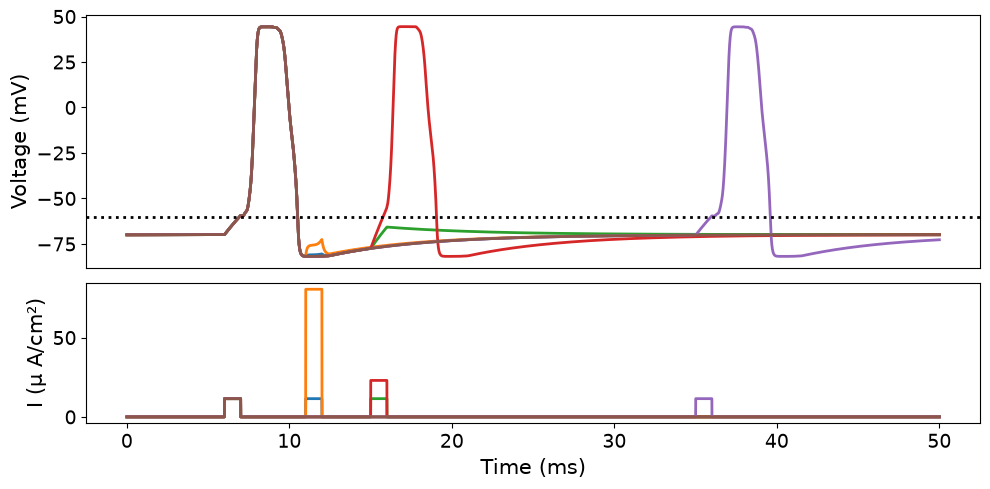

In [9]:
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# Parameters
# ============================================================
T = 50
p = 10**3
dt = 1 / p

V_Na = 45
V_K = -82
V0 = -70

Cm = 1
V_th = -60

G_Namin = 0.01600
V_cut = -18.00000

C_Na = 36.96
C_K = 13.125

tau_m = 0.19903
tau_h = 2.75768
tau_K = 2

G_Kmin = 9.5 * G_Namin

# ============================================================
# Time
# ============================================================
Tt = np.arange(0, T + dt, dt)

# ============================================================
# Stimulation protocols
# ============================================================
I_stim = 11.5

protocols = [
    [(6, 7, I_stim),       (11, 12, I_stim)],
    [(6, 7, I_stim),       (11, 12, 7 * I_stim)],
    [(6, 7, I_stim),       (15, 16, I_stim)],
    [(6, 7, I_stim),       (15, 16, 2 * I_stim)],
    [(6, 7, I_stim),       (35, 36, I_stim)],
    # single pulse
    [(6, 7, I_stim)]
]

# ============================================================
# Figure
# ============================================================
fig, axs = plt.subplots(
    2, 1,
    figsize=(10, 5),
    sharex=True,
    gridspec_kw={'height_ratios': [1.8, 1]}
)

# ============================================================
# Run simulations
# ============================================================
for j, protocol in enumerate(protocols):

    # --------------------------------------------------------
    # Initialize variables for this simulation
    # --------------------------------------------------------
    V = V0 * np.ones_like(Tt)

    m = np.zeros_like(Tt)
    h = np.zeros_like(Tt)
    n = np.zeros_like(Tt)

    Gk = G_Kmin * np.ones_like(Tt)
    GNa = G_Namin * np.ones_like(Tt)

    I = np.zeros_like(Tt)

    # --------------------------------------------------------
    # Construct stimulus
    # --------------------------------------------------------
    for t_start, t_end, amplitude in protocol:
        i_start = int(t_start / dt)
        i_end = int(t_end / dt)

        I[i_start:i_end] = amplitude

    # --------------------------------------------------------
    # Maximum delay
    # --------------------------------------------------------
    hist = int(max(tau_m, tau_h, tau_K) / dt)

    # --------------------------------------------------------
    # Simulation loop
    # --------------------------------------------------------
    for i in range(len(Tt) - 1):

        # Delayed indices
        im = i - int(tau_m / dt)
        ih = i - int(tau_h / dt)
        iK = i - int(tau_K / dt)

        # Use V0 when delay reaches before t = 0
        Vm = V[im] if im >= 0 else V0
        Vh = V[ih] if ih >= 0 else V0
        VK = V[iK] if iK >= 0 else V0

        # ----------------------------------------------------
        # Gating variables
        # Same definitions as in the first code
        # ----------------------------------------------------
        h[i] = max(V_cut - Vh, 0) / (V_cut - V_K)

        m[i] = max(Vm - V_th, 0) / (V_Na - V_th)

        n[i] = max(VK - V_th, 0) / (V_Na - V_th)

        # ----------------------------------------------------
        # Conductances
        # ----------------------------------------------------
        GNa[i] = G_Namin + C_Na * m[i] * h[i]

        Gk[i] = G_Kmin + C_K * n[i]

        # ----------------------------------------------------
        # Voltage equation
        # ----------------------------------------------------
        dVdt = -1 / Cm * (
            Gk[i] * (V[i] - V_K)
            + GNa[i] * (V[i] - V_Na)
            - I[i]
        )

        V[i + 1] = V[i] + dt * dVdt

    # --------------------------------------------------------
    # Plot voltage
    # --------------------------------------------------------
    axs[0].plot(
        Tt,
        V,
        linewidth=2,
    )

    # --------------------------------------------------------
    # Plot stimulus
    # --------------------------------------------------------
    axs[1].plot(
        Tt,
        I,
        linewidth=2
    )

# ============================================================
# First subplot: Voltage
# ============================================================
axs[0].tick_params(axis='y', labelsize=14)

axs[0].set_ylabel(
    'Voltage (mV)',
    fontsize=15
)

axs[0].axhline(
    y=V_th,
    color='k',
    linestyle=':',
    linewidth=2,
)

# Hide x-axis labels on first subplot
axs[0].tick_params(
    axis='x',
    which='both',
    bottom=False,
    labelbottom=False
)

# ============================================================
# Second subplot: Stimulus
# ============================================================
axs[1].tick_params(
    axis='both',
    which='major',
    labelsize=14
)

axs[1].set_ylabel(
    'I (μ A/cm²)',
    fontsize=15
)

axs[1].set_xlabel(
    'Time (ms)',
    fontsize=15
)

plt.tight_layout()
plt.show()


#Figure 1.15 - Two contributions to refractoriness

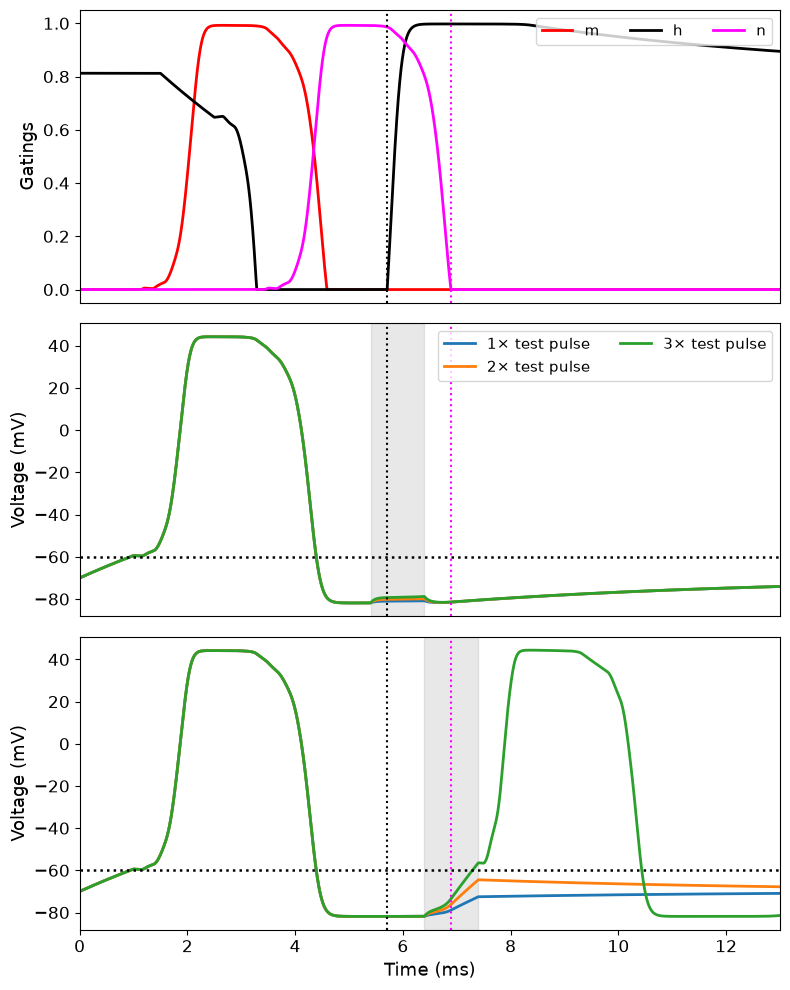


Refractory-period test summary:

Early / absolute-period test (S2 starts at 5.400 ms, duration 1.000 ms):
  1× test (11.5 μA/cm²): post-test peak = -76.32 mV; no second AP detected
  2× test (23.0 μA/cm²): post-test peak = -76.30 mV; no second AP detected
  3× test (34.5 μA/cm²): post-test peak = -76.28 mV; no second AP detected

Late / relative-period test (S2 starts at 6.400 ms, duration 1.000 ms):
  1× test (11.5 μA/cm²): post-test peak = -71.24 mV; no second AP detected
  2× test (23.0 μA/cm²): post-test peak = -64.48 mV; no second AP detected
  3× test (34.5 μA/cm²): post-test peak = 44.40 mV; second AP detected

S1-only: n first returns to zero at about 6.893 ms.
S1-only: h first recovers from zero at about 5.708 ms.

Caution: these are operational results for this delayed-algebraic model. The h gate is a delayed voltage mapping, not a dynamic sodium-inactivation state, so this does not establish a physiological absolute refractory period. Use brief S2 pulses and sweep their ons

In [10]:
import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------------------------------------------
# Model parameters
# ---------------------------------------------------------------------
T = 13.0                 # total simulation time (ms)
p = 10e3                 # time steps per ms
dt = 1.0 / p
t = np.arange(0.0, T + dt, dt)

V_Na = 45.0
V_K = -82.0
V0 = -70.0
Cm = 1.0
V_th = -60.0
V_cut = -18.0

G_Namin = 0.01600
C_Na = 36.96
C_K = 13.125
G_Kmin = 9.5 * G_Namin

# Fixed delays in the algebraic gating equations (ms).
tau_m = 0.199
tau_h = 1.5#2.758
tau_K = 2.5#1.15

I_stim = 11.5
first_stim_start = 0.0
first_stim_end = 1.0

# ---------------------------------------------------------------------
# Paired-pulse protocols
# ---------------------------------------------------------------------
# S1 is applied at 0--1 ms. Each independent trial receives only one S2.
# A short test pulse avoids maintaining a large depolarization until h recovers.
absolute_test_start = 5.4
relative_test_start = 6.4
test_duration = 1.0        # ms; changed from 1.0 ms to a brief test pulse
test_multipliers = [1.0, 2.0, 3.0]

protocols = {
    "Early / absolute-period test": absolute_test_start,
    "Late / relative-period test": relative_test_start,
}


def simulate(test_start=None, test_multiplier=0.0):
    """Simulate S1 alone or one independent S1-S2 trial."""
    V = np.full(t.shape, V0, dtype=float)
    m = np.zeros_like(t)
    h = np.zeros_like(t)
    n = np.zeros_like(t)
    I = np.zeros_like(t)

    # Conditioning stimulus S1: identical in every trial.
    I[(t >= first_stim_start) & (t < first_stim_end)] = I_stim

    # Optional test stimulus S2. Only one S2 is applied in each trial.
    if test_start is not None and test_multiplier > 0:
        I[(t >= test_start) & (t < test_start + test_duration)] = (
            test_multiplier * I_stim
        )

    delay_m = int(round(tau_m / dt))
    delay_h = int(round(tau_h / dt))
    delay_K = int(round(tau_K / dt))

    for i in range(t.size):
        # Delayed voltage values; use resting voltage before t=0.
        im = i - delay_m
        ih = i - delay_h
        iK = i - delay_K

        Vm = V[im] if im >= 0 else V0
        Vh = V[ih] if ih >= 0 else V0
        VK_delayed = V[iK] if iK >= 0 else V0

        # Gates are algebraic functions of the delayed voltage.
        m[i] = np.clip((Vm - V_th) / (V_Na - V_th), 0.0, 1.0)
        h[i] = np.clip((V_cut - Vh) / (V_cut - V_K), 0.0, 1.0)
        n[i] = np.clip((VK_delayed - V_th) / (V_Na - V_th), 0.0, 1.0)

        GNa_i = G_Namin + C_Na * m[i] * h[i]
        GK_i = G_Kmin + C_K * n[i]

        if i < t.size - 1:
            dVdt = -(
                GK_i * (V[i] - V_K)
                + GNa_i * (V[i] - V_Na)
                - I[i]
            ) / Cm
            V[i + 1] = V[i] + dt * dVdt

    return V, m, h, n, I


def first_transition(time, gate, condition, start=1.0, end=7.0):
    """Return first time where a Boolean transition condition is true."""
    candidates = np.flatnonzero(
        (time[:-1] >= start)
        & (time[:-1] < end)
        & condition(gate[:-1], gate[1:])
    )
    return float(time[candidates[0]]) if candidates.size else None


# ---------------------------------------------------------------------
# S1-only simulation: gates and reference landmarks are not affected by S2.
# ---------------------------------------------------------------------
Vg, mg, hg, ng, Ig = simulate()

t_h_recovery = first_transition(
    t,
    hg,
    lambda before, after: (before <= 0.0) & (after > 0.0),
)
t_K_close = first_transition(
    t,
    ng,
    lambda before, after: (before > 0.0) & (after <= 0.0),
)

# Independent S1-S2 simulations for every timing and amplitude.
results = {}
for protocol_name, test_start in protocols.items():
    for mult in test_multipliers:
        results[(protocol_name, mult)] = simulate(test_start, mult)

# One consistent colour per S2 amplitude.
cycle = plt.rcParams["axes.prop_cycle"].by_key()["color"]
colors = {mult: cycle[i % len(cycle)] for i, mult in enumerate(test_multipliers)}

# ---------------------------------------------------------------------
# Plot: (A) S1-only gates, (B) early test, (C) later test
# ---------------------------------------------------------------------
fig, axs = plt.subplots(3, 1, figsize=(8, 10), sharex=True)

# Panel A: gates from the conditioning pulse S1 alone.
axs[0].plot(t, mg, color="red", label="m", linewidth=2)
axs[0].plot(t, hg, color="black", label="h", linewidth=2)
axs[0].plot(t, ng, color="magenta", label="n", linewidth=2)
axs[0].set_ylabel("Gatings", fontsize=13)
axs[0].set_ylim(-0.05, 1.05)
axs[0].legend(fontsize=11, ncol=3, loc="upper right")
axs[0].tick_params(axis="both", which="major", labelsize=12)
axs[0].tick_params(axis="x", which="both", bottom=False, labelbottom=False)

# Panel B: early S2 to probe the absolute-refractory interval.
for mult in test_multipliers:
    V, _, _, _, _ = results[("Early / absolute-period test", mult)]
    axs[1].plot(
        t, V, color=colors[mult], linewidth=2,
        label=f"{mult:g}× test pulse",
    )
axs[1].axhline(V_th, color="black", linestyle=":", linewidth=1.8)
axs[1].axvspan(
    absolute_test_start, absolute_test_start + test_duration,
    color="grey", alpha=0.18,
)
axs[1].set_ylabel("Voltage (mV)", fontsize=13)
axs[1].tick_params(axis="y", labelsize=12)
axs[1].tick_params(axis="x", which="both", bottom=False, labelbottom=False)
axs[1].legend(fontsize=11, ncol=2, loc="best")

# Panel C: later S2 to probe relative refractoriness.
for mult in test_multipliers:
    V, _, _, _, _ = results[("Late / relative-period test", mult)]
    axs[2].plot(
        t, V, color=colors[mult], linewidth=2,
        label=f"{mult:g}× test pulse",
    )
axs[2].axhline(V_th, color="black", linestyle=":", linewidth=1.8)
axs[2].axvspan(
    relative_test_start, relative_test_start + test_duration,
    color="grey", alpha=0.18,
)
axs[2].set_ylabel("Voltage (mV)", fontsize=13)
axs[2].set_xlabel("Time (ms)", fontsize=13)
axs[2].tick_params(axis="both", which="major", labelsize=12)

# Landmarks from the S1-only gate trajectory.
for ax in axs:
    if t_K_close is not None:
        ax.axvline(t_K_close, color="magenta", linestyle=":", linewidth=1.5)
    if t_h_recovery is not None:
        ax.axvline(t_h_recovery, color="black", linestyle=":", linewidth=1.5)

axs[2].set_xlim(0, T)
plt.tight_layout()
plt.show()

# ---------------------------------------------------------------------
# Response check: count a second AP only if V crosses 0 mV after S2 ends.
# Use a 4-ms post-stimulus window to capture delayed responses consistently.
# ---------------------------------------------------------------------
print("\nRefractory-period test summary:")
for protocol_name, test_start in protocols.items():
    print(
        f"\n{protocol_name} (S2 starts at {test_start:.3f} ms, "
        f"duration {test_duration:.3f} ms):"
    )
    for mult in test_multipliers:
        V, _, _, _, _ = results[(protocol_name, mult)]
        response_start = test_start + test_duration
        response_end = min(T, response_start + 4.0)
        mask = (t >= response_start) & (t <= response_end)
        peak_after_test = float(np.max(V[mask]))
        fired = bool(np.any(V[mask] >= 0.0))
        print(
            f"  {mult:g}× test ({mult * I_stim:.1f} μA/cm²): "
            f"post-test peak = {peak_after_test:.2f} mV; "
            f"{'second AP detected' if fired else 'no second AP detected'}"
        )

if t_K_close is not None:
    print(f"\nS1-only: n first returns to zero at about {t_K_close:.3f} ms.")
if t_h_recovery is not None:
    print(f"S1-only: h first recovers from zero at about {t_h_recovery:.3f} ms.")

print(
    "\nCaution: these are operational results for this delayed-algebraic model. "
    "The h gate is a delayed voltage mapping, not a dynamic sodium-inactivation "
    "state, so this does not establish a physiological absolute refractory period. "
    "Use brief S2 pulses and sweep their onset time to estimate the refractory interval."
)


# Figure 1.16 -  Numerical strength–interval curve

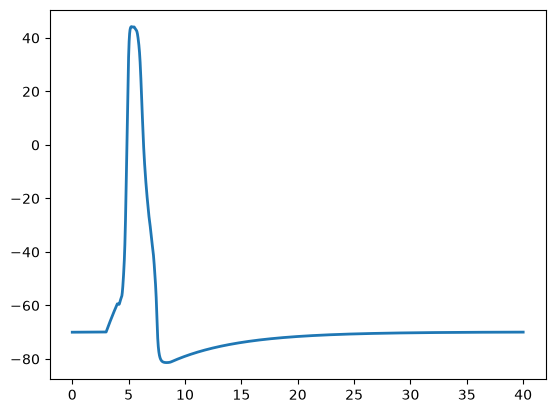

In [11]:
import numpy as np
import matplotlib.pyplot as plt

T = 40
p = 10**3
dt = 1/p
V_Na = 45
V_K = -82
V0 = -70
Cm = 1
V_th = -60
G_Namin = 0.01600
V_cut = -18.00000
C_Na = 36.96
C_K = 13.125
tau_m = 0.19903
tau_h = 2.75768
tau_K = 1.3
G_Kmin = 9.5 * G_Namin

Tt = np.arange(0, T + dt, dt)

V = V0 * np.ones_like(Tt)
m = np.zeros_like(Tt)
h = np.zeros_like(Tt)
n = np.zeros_like(Tt)
Gk = G_Kmin * np.ones_like(Tt)
GNa = G_Namin * np.ones_like(Tt)
I = np.zeros_like(Tt)

I_stim = 11.5; factor=2.692; k=5.1
for i in range(int(3 / dt), int(4 / dt)):
    I[i] = I_stim

#for i in range(int((3+k)/ dt), int((4+k)/ dt)):
#    I[i] = factor*I_stim

for i in range(len(Tt) - 1):

    im = i - int(tau_m * p)
    ih = i - int(tau_h * p)
    iK = i - int(tau_K * p)

    Vm = V[im] if im >= 0 else V0
    Vh = V[ih] if ih >= 0 else V0
    VK = V[iK] if iK >= 0 else V0

    h[i] = max(V_cut - Vh, 0) / (V_cut - V_K)
    m[i] = max(Vm - V_th, 0) / (V_Na - V_th)
    n[i] = max(VK - V_th, 0) / (V_Na - V_th)

    GNa[i] = G_Namin + C_Na * m[i] * h[i]
    Gk[i] = G_Kmin + C_K * n[i]

    dVdt = -1 / Cm * (Gk[i] * (V[i] - V_K) + GNa[i] * (V[i] - V_Na) -  I[i])
    V[i + 1] = V[i] + dt * dVdt

plt.plot(Tt, V, linewidth=2)
plt.show()

In [12]:
for i in range(len(Tt)-1):
      if h[i]<=0 and h[i+1]>0:
        b=i*dt-3
        print(b) #end inactivation

for i in range(len(Tt)-1):
      if n[i]>0 and n[i+1]<=0:
        c=i*dt-3
        print(c) #closing the potassium channels

6.364000000000001
5.772


0.7720000000000002
0.6720000000000006
0.5220000000000002
0.27200000000000024


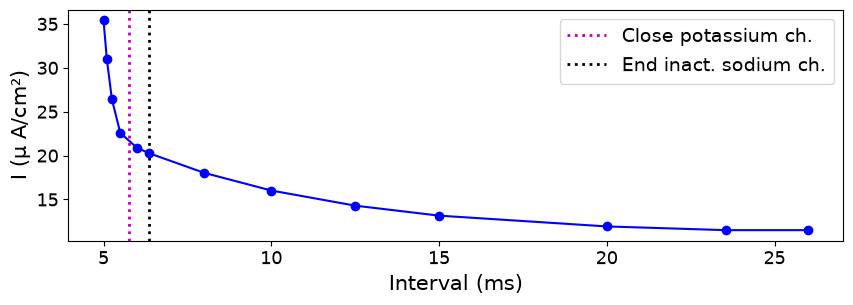

In [13]:
import matplotlib.pyplot as plt
import numpy as np
import math
plt.figure(figsize=(10, 3))

pontos = np.array([
#(4.78,4.62),
#(4.85,3.98),
(5,3.081),
(5.1,2.692),
(5.25,2.297),
(5.5,1.963),
(6,1.816),
(6.37,1.761),
(8,1.568),
(10,1.393),
(12.5,1.243),
(15,1.144),
(20, 1.037),
(23.55, 1),
(26,1),
])

x = pontos[:, 0]
y = pontos[:, 1]

t_star =[5,5.1,5.25,5.5,6,6.37,8,10,12.5,15,20,23.55,26]

G_total=G_Kmin+G_Namin
V_eq_line=((G_Kmin+C_K)*V_K+G_Namin*V_Na)/(G_Kmin+C_K+G_Namin)

I_1 = []
I_2=[]

for t in [5,5.1,5.25,5.5]:
    A=(V_th-V0)
    B=(V[int((t+3)/dt)] - V0) * math.exp(-G_total)
    print(c-t)
    C=G_total/(1-math.exp(-(G_total)*(1-(c-t))))
    I_1.append((A-B)*C)

for t in [6,6.37,8,10,12.5,15,20,23.55,26]:
    A=(V_th-V0)
    B=(V[int((t+3)/dt)] - V0) * math.exp(-G_total)
    C=G_total/ (1 - math.exp(-G_total))
    I_2.append((A-B)*C)


plt.axvline(x=c, color='m', linestyle=':', linewidth=2,label=f'Close potassium ch.')
plt.axvline(x=b, color='k', linestyle=':', linewidth=2,label=f'End inact. sodium ch.')

plt.plot(x, y*11.5, marker='o', linestyle='-', color='blue')#,label=f'Numerical')

#plt.plot(t_star, I_1+I_2, marker='o', linestyle=':', color='r',label=f'Analytical')

plt.xlabel('Interval (ms)', fontsize=15)
plt.ylabel(fr'I (μ A/cm²)', fontsize=15)

plt.tick_params(axis='both', which='major', labelsize=13)

plt.legend(prop={'size': 14})
plt.show()
